In [18]:
#프로헷
#prophet 시계열데이터를 다루기위한 별도의 모델 


In [19]:
%pip install prophet

Note: you may need to restart the kernel to use updated packages.



[notice] A new release of pip is available: 24.0 -> 26.3
[notice] To update, run: python.exe -m pip install --upgrade pip


In [20]:
from prophet import Prophet
import pandas as pd
#시계열 데이터 준비
df=pd.DataFrame({"ds":["2023-01-01","2023-01-02","2023-01-03","2023-01-04"],"y":[10,11,9,12]})
df['ds']=pd.to_datetime(df["ds"])

In [21]:
model=Prophet()
model.fit(df)

09:34:44 - cmdstanpy - INFO - Chain [1] start processing
09:34:44 - cmdstanpy - INFO - Chain [1] done processing


In [22]:
future=model.make_future_dataframe(periods=365)

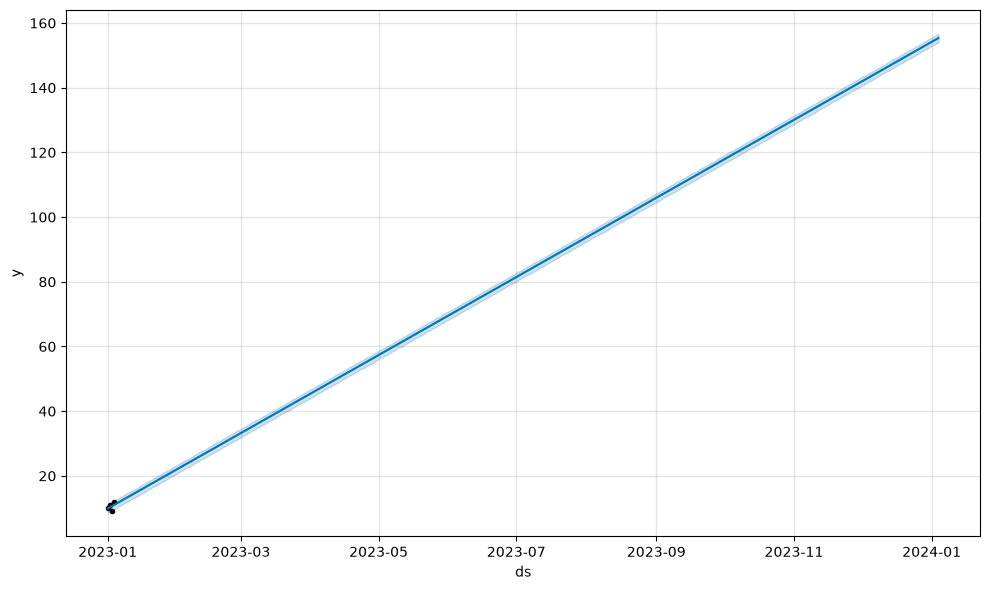

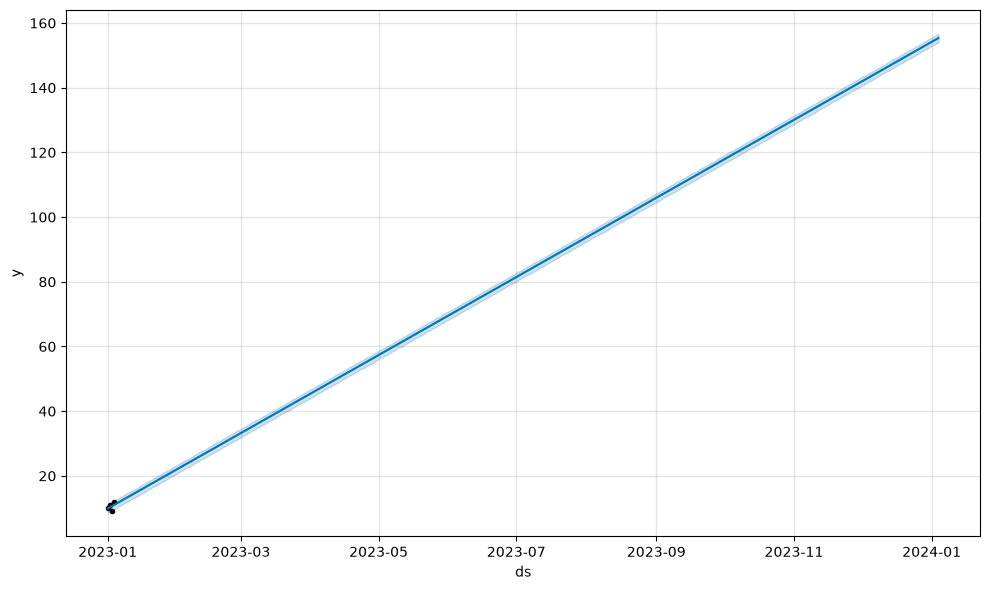

In [23]:
forecast=model.predict(future)
model.plot(forecast)

### Prophet에서 사용하는 주요 메소드들
- fit(df)
    - Prophet 모델에 데이터를 적합시키는 메소드다. df는 예측할 시계열 데이터로, ds(날짜)와 y(값)를 포함하는 데이터프레임이다.
- predict(future)
    - 주어진 미래 데이터를 기반으로 예측을 수행하는 메소드다. future는 예측할 기간에 대한 날짜 정보를 포함하는 데이터프레임으로, Prophet은 이를 사용해 미래의 값을 예측한다.
- make_future_dataframe(periods=n)
    - 미래 예측을 위한 날짜 데이터프레임을 생성한다. n은 예측할 기간의 길이를 나타내며, 예측하고자 하는 날짜 범위에 해당한다.
- add_seasonality(name, period, fourier_order)
    - 사용자 정의 계절성을 추가하는 메소드입니다. name은 계절성의 이름, period는 계절성의 주기(예: 365.25), fourier_order는 푸리에 급수의 차수를 지정한다. 이를 통해 기본 제공되는 연간, 주간 계절성 외에 추가적인 주기 패턴을 모델에 반영할 수 있다.
- plot(fcst)
    - Prophet 모델의 예측 결과를 시각화하는 메소드다. 예측된 값(fcst)을 시각적으로 표현하며, 추세, 계절성, 변화점 등을 직관적으로 확인할 수 있다.
- plot_components(fcst)
    - Prophet 모델의 각 성분(추세, 계절성, 휴일 효과 등)을 분해하여 시각화하는 메소드다. 이 메소드를 통해 각 성분이 시계열에 어떻게 기여하는지 확인할 수 있다.

In [24]:
###예제2
import pandas as pd
df=pd.read_csv("./AAPL.csv")
df.head()

,Date,Open,High,Low,Close,Adj Close,Volume
0,1980-12-12,0.128348,0.128906,0.128348,0.128348,0.100323,469033600
1,1980-12-15,0.122210,0.122210,0.121652,0.121652,0.095089,175884800
2,1980-12-16,0.113281,0.113281,0.112723,0.112723,0.088110,105728000
3,1980-12-17,0.115513,0.116071,0.115513,0.115513,0.090291,86441600
4,1980-12-18,0.118862,0.119420,0.118862,0.118862,0.092908,73449600


In [25]:
df["ds"]=df["Date"]
df["y"]=df["Close"]

In [26]:
data=df[["ds","y"]]
data=data[-1000:]
data["ds"]=pd.to_datetime(data["ds"])

In [27]:
from prophet import Prophet
prophet_m=Prophet().fit(data)

09:34:44 - cmdstanpy - INFO - Chain [1] start processing
09:34:44 - cmdstanpy - INFO - Chain [1] done processing


In [28]:
future=prophet_m.make_future_dataframe(periods=365)


In [29]:
future.tail()


,ds
1360,2023-03-20
1361,2023-03-21
1362,2023-03-22
1363,2023-03-23
1364,2023-03-24


In [ ]:
forecast=prophet_m.predict(future)
forecast[["ds","yhat","yhat_lower","yhat_upper"]].tail()
#yhat:예측값 lower하한선 upper 하한선

,ds,yhat,yhat_lower,yhat_upper
1360,2023-03-20,202.707377,152.679701,255.335664
1361,2023-03-21,203.056528,154.196528,253.892567
1362,2023-03-22,203.281984,152.494408,255.786765
1363,2023-03-23,203.226603,151.838564,255.662271
1364,2023-03-24,203.136565,152.842662,255.480045


In [32]:
print("컬럼목록",forecast.columns.tolist())

컬럼목록 ['ds', 'trend', 'yhat_lower', 'yhat_upper', 'trend_lower', 'trend_upper', 'additive_terms', 'additive_terms_lower', 'additive_terms_upper', 'weekly', 'weekly_lower', 'weekly_upper', 'yearly', 'yearly_lower', 'yearly_upper', 'multiplicative_terms', 'multiplicative_terms_lower', 'multiplicative_terms_upper', 'yhat']


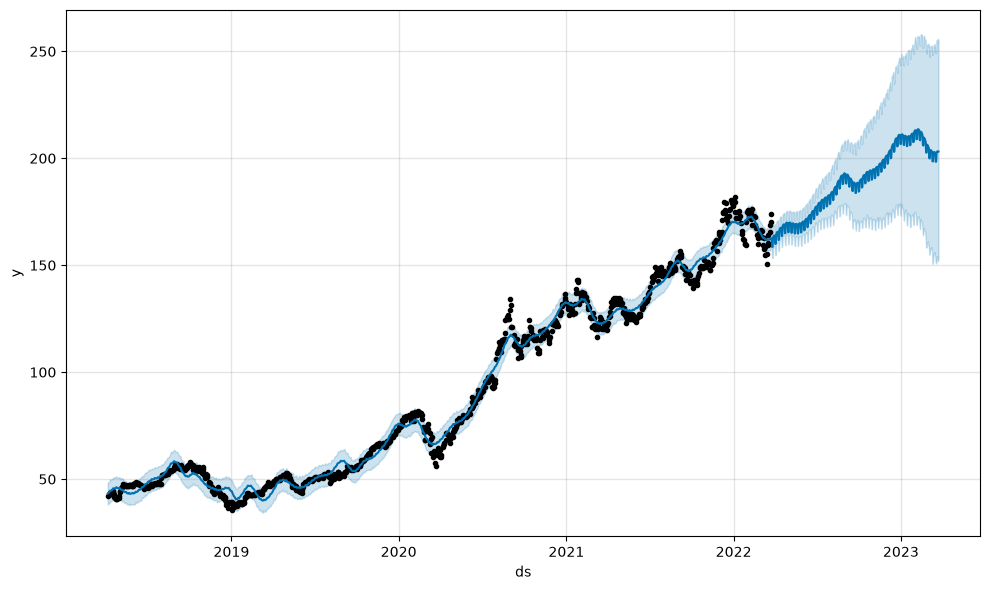

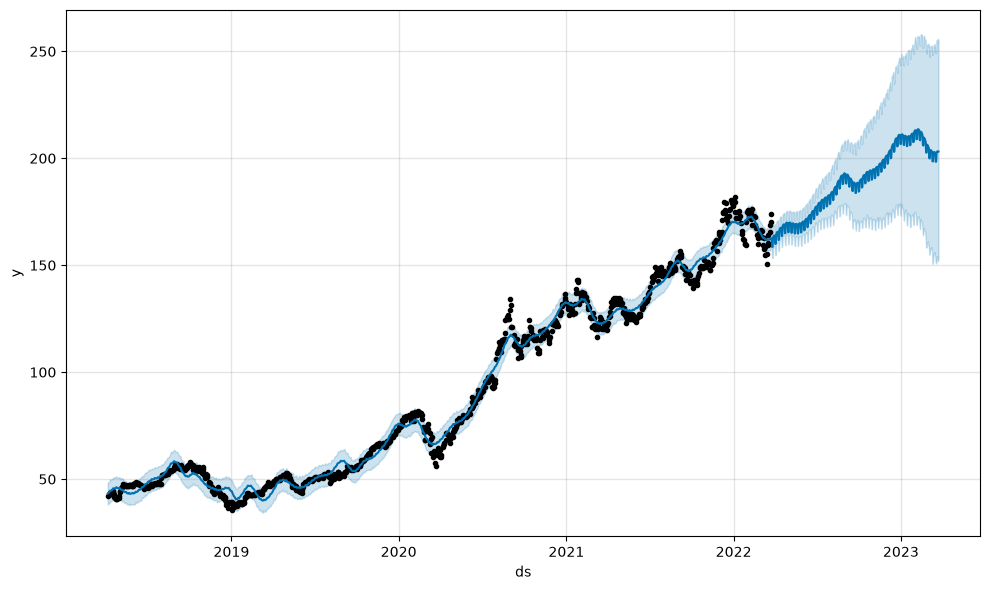

In [33]:
prophet_m.plot(forecast)

In [34]:
#자동차 판매량 데이터

import pandas as pd
path = 'https://raw.githubusercontent.com/jbrownlee/Datasets/master/monthly-car-sales.csv'
df=pd.read_csv(path,header=0)
print(df.shape)
print(df.head())

(108, 2)
     Month  Sales
0  1960-01   6550
1  1960-02   8728
2  1960-03  12026
3  1960-04  14395
4  1960-05  14587


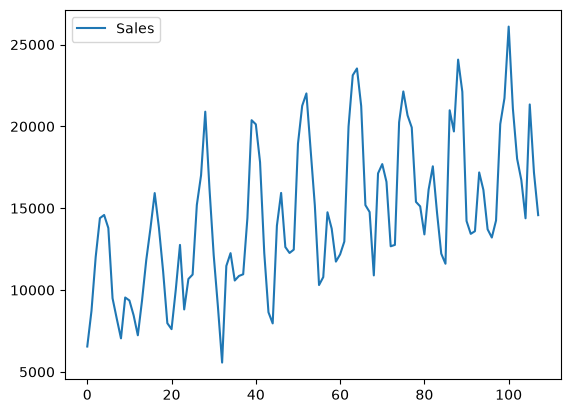

In [36]:
from matplotlib import pyplot

df.plot()
pyplot.show()

In [38]:
df.columns=["ds","y"]
df["ds"]=pd.to_datetime(df["ds"])

In [40]:
from prophet import Prophet
model=Prophet()
model.fit(df)

09:43:09 - cmdstanpy - INFO - Chain [1] start processing
09:43:09 - cmdstanpy - INFO - Chain [1] done processing


In [41]:
last_1year=list()
for i in range(1,13):
    last_1year.append(["1990-%02d" %i ])
last_1year=pd.DataFrame(last_1year,columns=["ds"])
last_1year["ds"]=pd.to_datetime(last_1year["ds"])

In [42]:
last_1year["ds"]

0    1990-01-01
1    1990-02-01
2    1990-03-01
3    1990-04-01
4    1990-05-01
5    1990-06-01
6    1990-07-01
7    1990-08-01
8    1990-09-01
9    1990-10-01
10   1990-11-01
11   1990-12-01
Name: ds, dtype: datetime64[ns]

In [43]:
forecast=model.predict(last_1year)

In [44]:
print(forecast[["ds","yhat","yhat_lower","yhat_upper"]].head())


          ds          yhat    yhat_lower    yhat_upper
0 1990-01-01  28703.105594  27249.994481  30433.793525
1 1990-02-01  29401.513205  27849.113851  30928.270361
2 1990-03-01  34666.103385  33157.420691  36259.555440
3 1990-04-01  36891.509809  35430.946395  38248.317874
4 1990-05-01  38607.910070  37133.505888  40191.086185


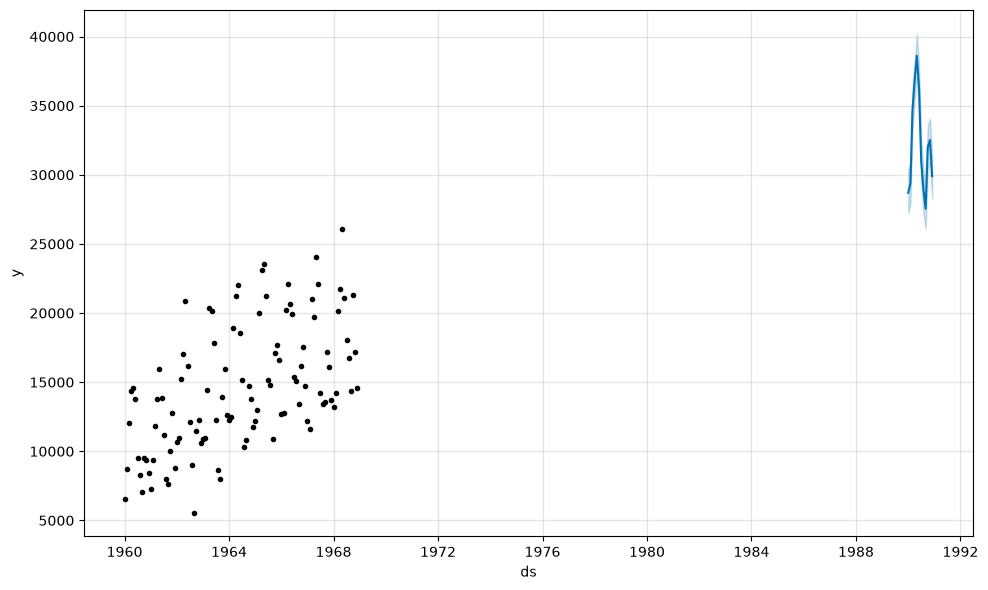

In [45]:
model.plot(forecast)
pyplot.show()

In [48]:
last_1year=list()
for i in range(1,13):
    last_1year.append(["1968-%02d" %i ])
last_1year=pd.DataFrame(last_1year,columns=["ds"])
last_1year["ds"]=pd.to_datetime(last_1year["ds"])
last_1year["ds"]

0    1968-01-01
1    1968-02-01
2    1968-03-01
3    1968-04-01
4    1968-05-01
5    1968-06-01
6    1968-07-01
7    1968-08-01
8    1968-09-01
9    1968-10-01
10   1968-11-01
11   1968-12-01
Name: ds, dtype: datetime64[ns]

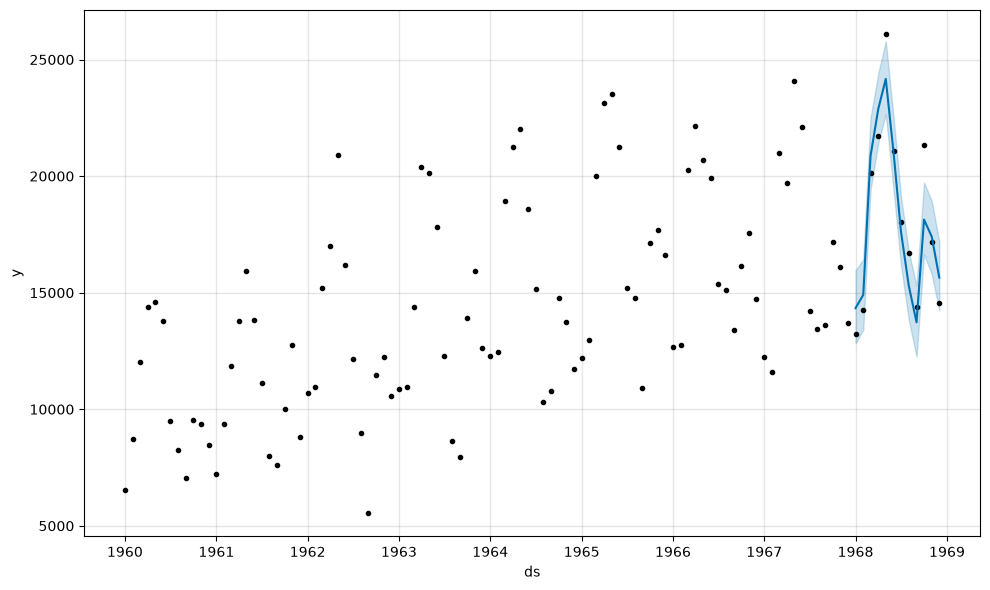

In [50]:
forecast=model.predict(last_1year)
model.plot(forecast)
pyplot.show()

In [58]:
future=model.make_future_dataframe(
    periods=12,
    freq="MS",
    include_history=False
)
future

,ds
0,1968-01-01
1,1968-02-01
2,1968-03-01
3,1968-04-01
4,1968-05-01
5,1968-06-01
6,1968-07-01
7,1968-08-01
8,1968-09-01
9,1968-10-01


In [ ]:
#모델성능평가

In [51]:
train =df.drop(df.index[-12:])
y_true=df["y"][-12:].values

In [52]:
model=Prophet()
model.fit(train)

09:59:29 - cmdstanpy - INFO - Chain [1] start processing
09:59:29 - cmdstanpy - INFO - Chain [1] done processing


In [53]:
last_1year=list()
for i in range(1,13):
    last_1year.append(["1968-%02d" %i])
last_1year=pd.DataFrame(last_1year,columns=["ds"])
last_1year["ds"]=pd.to_datetime(last_1year["ds"])

In [54]:
forecast=model.predict(last_1year)
y_pred=forecast["yhat"].values

In [55]:
from sklearn.metrics import mean_absolute_error
mae=mean_absolute_error(y_true,y_pred)
print("MAE %.3f " % mae)
#mae 원래값단위 유지 ->평균적으로 얼마나 벗어나는지
#큰예측오차를 최소화시킬때 mse ->큰오차가 얼마나 벗어나는지

MAE 1336.814 


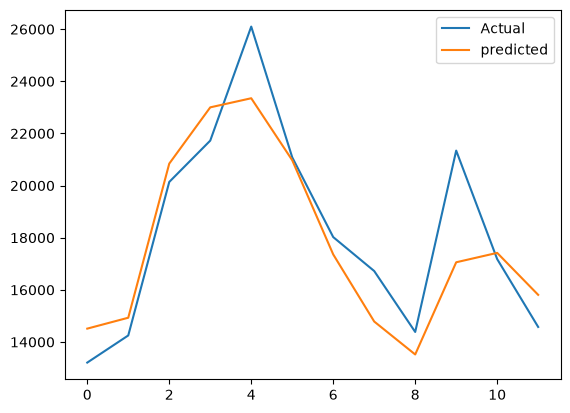

In [57]:
pyplot.plot(y_true,label="Actual")
pyplot.plot(y_pred,label="predicted")
pyplot.legend()
pyplot.show()